(paramfit_pocomc_ntbk)=

# Parameters fit with pocoMC

This is an example of how we can combine the **ASteCA** synthetic clusters with a likelihood defined by the user and an external sampler, here [pocoMC](https://pocomc.readthedocs.io/) (Preconditioned Monte Carlo, used here without its normalizing flow preconditioning, see below), to estimate the fundamental parameters of an observed cluster.

**ASteCA** includes its own sampler, adapted from pocoMC and with a built-in likelihood that was tested and calibrated with it (see the [Parameters fit with asteca.Sampler](paramfit_sampler_ntbk) tutorial). This tutorial shows instead how to use any other likelihood and sampler. pocoMC needs to be installed separately (`pip install pocomc`); here's a list with many other Python-based [MCMC and ABC packages](https://gabriel-p.github.io/pythonMCMC/).

## Loading ASteCA objects

We start by instantiating an [Isochrones](asteca.Isochrones) object with a PARSEC isochrone. This is an example file but you can use whatever isochrone service fits your needs:

In [1]:
import asteca

# Load isochrones
isochs = asteca.Isochrones(
    model='parsec',
    isochs_path="../../_static/isochrones/parsec/",
    mag="Gmag",
    color=("G_BPmag", "G_RPmag"),
    magnitude_effl=6390.7,
    color_effl=(5182.58, 7825.08),
    verbose=2
)


Instantiating isochrones
Model          : PARSEC
N_files        : 1
N_mets         : 5
N_ages         : 13
N_points       : 2000
z    range     : [0.01, 0.03]
loga range     : [7.0, 10.0]
Magnitude      : Gmag
Color          : G_BPmag-G_RPmag
Isochrone object generated


Next we instantiate a [Synthetic](asteca.Synthetic) object, passing the `isochs` object we just created (we are using all defaults for the arguments here):

In [2]:
# Create Synthetic cluster object
synthcl = asteca.Synthetic(isochs, seed=457304, verbose=2)


Instantiating synthetic
(Sampling IMF)
Default params : {'met': 0.0152, 'loga': 8.0, 'alpha': 0.09, 'beta': 0.94, 'Rv': 3.1, 'DR': 0.0, 'Av': 0.2, 'dm': 9.0}
Extinction law : CCMO
Diff reddening : foreground
IMF            : chabrier_2014
Max init mass  : 10000
Gamma dist     : D&K
Random seed    : 457304
Synthetic clusters object generated


Now we load our observed cluster into a [Cluster](asteca.Cluster) object:

In [3]:
import pandas as pd

obs_df = pd.read_csv("../../_static/cluster.csv")

my_cluster = asteca.Cluster(
    ra=obs_df["RA_ICRS"],
    dec=obs_df["DE_ICRS"], 
    mag=obs_df["Gmag"],
    e_mag=obs_df["e_Gmag"],
    color=obs_df["BP-RP"],
    e_color=obs_df["e_BP-RP"],
    verbose=2
)


Instantiating cluster from data
Columns read   : ra, dec, mag, e_mag, color, e_color
N_stars        : 1428
N_nan_phot     : 9
N_clust_min    : 25
N_clust_max    : 2000
Cluster object generated


We assume that the cluster file loaded in `obs_df` is composed of only the most probable members of the cluster. If not, you can refer to the [Membership probabilities](membership) tutorial to learn how to obtain the membership probabilities and select the most probable members.

Finally, we need to calibrate our `synthcl` object with the `my_cluster` object we generated above. This adjusts the synthetic clusters to the observed one: same number of stars, maximum magnitude, and photometric uncertainties.

In [4]:
# Calibrate the `synthcl` object
synthcl.calibrate(my_cluster)


Calibrated observed cluster
N_stars_obs    : 1419
Max magnitude  : 18.99
Error distribution loaded


## Defining the priors

We are now ready to estimate the fundamental parameters with pocoMC. The first step is to define the priors for the parameters that are being estimated. The parameters that are *not* estimated keep the default values shown when the `synthcl` object was created.

pocoMC accepts any list of `scipy.stats` distributions as priors. Notice that, as in the pyABC case, the uniform distributions in `scipy.stats` require the minimum value and the *range*, not the maximum value.

In [5]:
import numpy as np
import pocomc
from scipy import stats

# Ranges for the fitted parameters
priors_dict = {
    "met": (0.01, 0.02),
    "loga": (7.0, 9.5),
    "dm": (8.0, 10.5),
    "Av": (0.0, 2.0),
}
names = list(priors_dict)

# Uniform priors for all the parameters. The user can of course change this as desired,
# see the pocoMC docs for more information.
prior = pocomc.Prior(
    [stats.uniform(pmin, pmax - pmin) for pmin, pmax in priors_dict.values()]
)

## Defining the likelihood

Next we define our own likelihood. Any function that compares the observed and synthetic clusters can be used here. We use the Poisson likelihood ratio of [Dolphin (2002)](https://ui.adsabs.harvard.edu/abs/2002MNRAS.332...91D), a common choice to compare a binned observed CMD (Hess diagram) with a model. The observed and synthetic stars are binned into a fixed Hess diagram (the CMD split into cells, spanning the observed cluster), and the log-likelihood is:

$$
\ln L = -\sum_i \left[m_i - n_i + n_i \ln\left(\frac{n_i}{m_i}\right)\right]
$$

where $n_i$ and $m_i$ are the number of observed and synthetic stars in cell $i$ (the last term is `0` when $n_i=0$). Its maximum value is `0`, obtained when $m_i=n_i$ in all the cells. Once calibrated, the `synthcl` object generates synthetic clusters with the same number of stars as the observed cluster, so the counts can be compared directly. Synthetic stars outside of the observed CMD do not fall in any cell, which lowers the likelihood. A small floor is added to $m_i$ to avoid $\ln(0)$ in the cells with observed stars and no synthetic stars.

The observed Hess diagram does not change during the run, so we compute it only once:

In [6]:
# Observed stars with valid photometry
msk = np.isfinite(my_cluster.mag) & np.isfinite(my_cluster.color)
obs_mag, obs_col = my_cluster.mag[msk], my_cluster.color[msk]

# Fixed Hess diagram, spanning the observed CMD
mag_edges = np.linspace(obs_mag.min(), obs_mag.max(), 21)
col_edges = np.linspace(obs_col.min(), obs_col.max(), 16)
n_obs = np.histogram2d(obs_mag, obs_col, bins=(mag_edges, col_edges))[0]
# Positions of the cells with observed stars, and the n*ln(n) term of these cells
nz = n_obs > 0
n_nz = n_obs[nz]
n_ln_n = n_nz * np.log(n_nz)
# Floor for the number of synthetic stars in a cell
m_floor = 0.1


def poisson_lkl(synth):
    """Poisson likelihood ratio (Dolphin 2002) between the observed cluster and a
    synthetic cluster, whose first two rows are its magnitude and color. The maximum
    value is 0 (same number of stars in every cell)."""
    if synth.size == 0:
        # Empty synthetic cluster
        m = np.zeros_like(n_obs)
    else:
        m = np.histogram2d(synth[0], synth[1], bins=(mag_edges, col_edges))[0]
    m_nz = np.maximum(m[nz], m_floor)
    # The cells with no observed stars only add their m_i term
    return -(m.sum() - m[nz].sum() + np.sum(m_nz - n_nz + n_ln_n - n_nz * np.log(m_nz)))

The log-likelihood function passed to pocoMC takes an array with the values of the fitted parameters, in the same order as the priors above. With `vectorize=True` (see below) pocoMC passes all the active particles of a step in a single call, as an array of shape `(n_active, n_params)`. These are generated at once with the `batch=True` argument of the [generate()](asteca.Synthetic.generate) method, which returns the same synthetic clusters as generating each particle separately. With [numba](https://numba.pydata.org/) installed it removes the Python overhead of each synthetic cluster (**without numba there is no speedup**). The first call includes the compilation of the numba functions, which are then cached for later sessions.

A likelihood computed with all the stars treats the synthetic clusters as an exact model of the observed one. This is not the case for a real cluster, and for clusters with many members the uncertainties of the parameters can be too small. A simple way to account for this is to divide the log-likelihood by a `temperature` $T>1$, which widens the posterior by a factor of about $\sqrt{T}$. We set it with the same rule that `asteca.Sampler` uses with `temperature="auto"`: $T=1$ for $N\leq 150$, $T=2$ for $150<N\leq 400$, and $T=4$ above. This rule was calibrated for the built-in likelihood of `asteca.Sampler`, not for this one, so it is only used here as an example: the users should choose a value suited to their own likelihood and data.

In [7]:
# Temperature as a function of the number of members, as (max N, temperature)
# pairs: the first pair with N <= max N applies
N_temperatures = ((150, 1.0), (400, 2.0), (np.inf, 4.0))
temperature = next(T for N_max, T in N_temperatures if obs_mag.size <= N_max)
print(f"N={obs_mag.size}, temperature={temperature:g}")


def log_like(params_arr):
    """Log-likelihood of an array of fitted parameters, of shape (n_active, n_params)"""
    # Generate one synthetic cluster per set of parameters
    synth_list = synthcl.generate(dict(zip(names, params_arr.T)), batch=True)
    # Tempered log-likelihood of each synthetic cluster (0 means a perfect match)
    lnl = np.array([poisson_lkl(synth) for synth in synth_list]) / temperature
    # Non-finite values are not expected; reject them as a safety check
    lnl[~np.isfinite(lnl)] = -np.inf
    return lnl

N=1419, temperature=4


## Running pocoMC

We create a [Sampler](https://pocomc.readthedocs.io/en/latest/api.html) object with the priors and the log-likelihood function. The `n_effective` and `n_active` arguments set the number of particles used; we use the same values as `asteca.Sampler` (256 and 128, with `n_total=512`). We turn off the preconditioning (`precondition=False`) because training the normalizing flow is slow on a CPU and, for this problem, it gives the same results.

The run stops when the posterior is reached and `n_total` effective samples are available:

In [8]:
import time

sampler = pocomc.Sampler(
    prior,
    log_like,
    n_effective=256,
    n_active=128,
    precondition=False,
    vectorize=True,
    random_state=457304,
)
t0 = time.perf_counter()
sampler.run(n_total=512, n_evidence=0, progress=False)
print(f"Run time: {time.perf_counter() - t0:.1f} s")

Run time: 17.4 s


## Extracting the results

We extract the posterior samples and their importance weights. We use the weights to show the effective sample size, which should be large enough to allow decent median/STDDEV values to be extracted.

In [9]:
# Weighted posterior samples
samples, weights, _, _ = sampler.posterior()

ESS = weights.sum() ** 2 / (weights**2).sum()
print("Effective sample size: {:.0f}".format(ESS))

Effective sample size: 612


The estimations for each fitted parameter are obtained from the resampled (i.e. equally weighted) posterior samples:

In [10]:
# Equally weighted posterior samples
samples, _, _ = sampler.posterior(resample=True)

print("\nParameters estimation:")
print("----------------------")
fit_params = {}
for i, k in enumerate(names):
    # Extract medians for the fitted parameters
    _median = np.median(samples[:, i])
    fit_params[k] = _median
    # Extract STDDEV for the fitted parameters
    _std = np.std(samples[:, i])
    print("{:<5}: {:.3f} +/- {:.3f}".format(k, _median, _std))


Parameters estimation:
----------------------
met  : 0.014 +/- 0.001
loga : 7.956 +/- 0.027
dm   : 8.126 +/- 0.038
Av   : 0.463 +/- 0.039


pocoMC does not include its own plotting functions, but the samples can be passed to any package. Here we use [corner](https://corner.readthedocs.io/) to show the 1D and 2D posterior distributions:

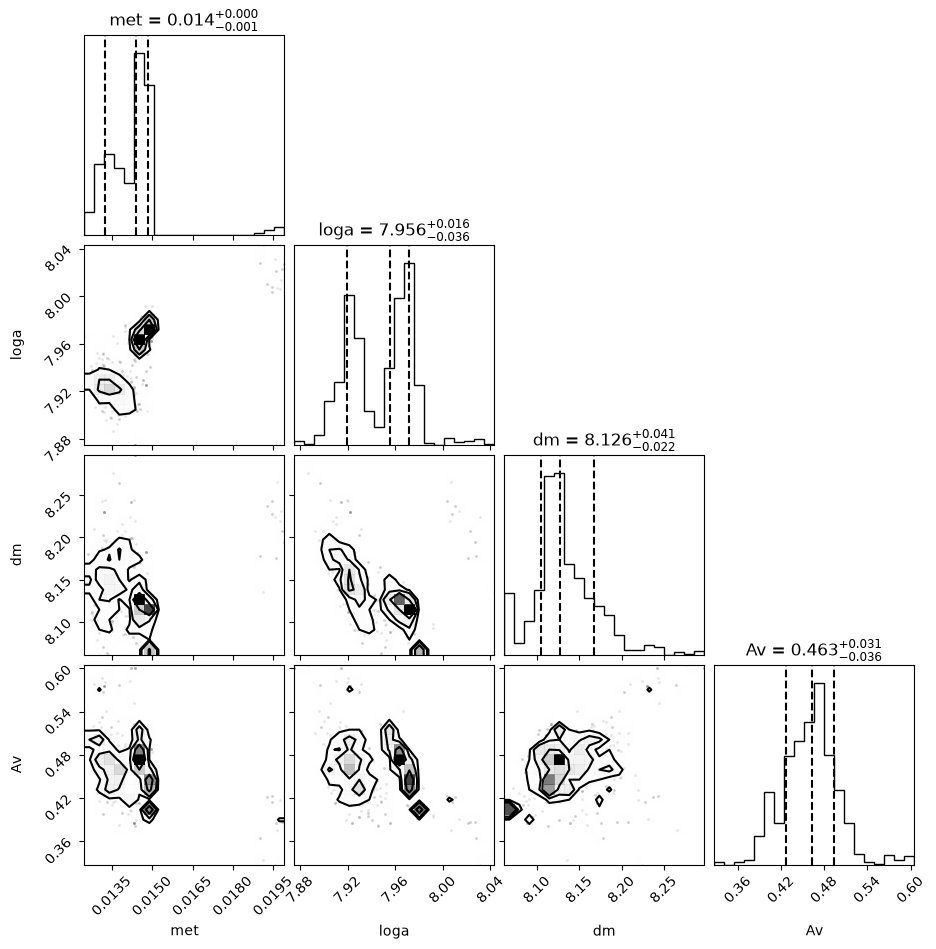

In [11]:
import corner

corner.corner(
    samples,
    labels=names,
    quantiles=(0.16, 0.5, 0.84),
    show_titles=True,
    title_fmt=".3f",
);

See the [Goodness of fit](paramfit_gof_ntbk) tutorial to assess whether the synthetic cluster generated with these parameters is a good representation of the observed cluster.